# 2D frequency-domain full-waveform inversion

Full-waveform inversion (FWI) fits the recorded wavefield itself, not just
first-arrival times. It can resolve much finer detail than traveltime
tomography, but its misfit is highly nonlinear. If the starting model
predicts arrivals more than half a period away from the observed ones, a
local optimizer locks onto the wrong cycle ("cycle skipping").

The standard workflow, used here, is:

1. **Traveltime tomography** (`simpeg_seismic.traveltime.SimulationEikonal`)
   for a smooth starting model that gets the arrival times right.
2. **Multi-frequency FWI** (`simpeg_seismic.frequency_domain.SimulationAcoustic`),
   from low to high frequencies: low frequencies have long periods and are
   forgiving of starting-model errors, and each band gives a better start for
   the next.

At the end, we show what happens when FWI starts from a homogeneous model
with only the high frequencies.

The inversion parameter is log-velocity, which keeps the velocity positive.
The simulations use slowness internally; maps connect the two.

In [1]:
import warnings

import discretize
import matplotlib.pyplot as plt
import numpy as np
import scipy.sparse as sp
from simpeg import (
    data_misfit,
    directives,
    inverse_problem,
    inversion,
    maps,
    optimization,
    regularization,
)
from simpeg.utils import get_default_solver

from simpeg_seismic import frequency_domain, traveltime
from simpeg_seismic.utils import wavelets

warnings.filterwarnings("ignore", category=FutureWarning)

## Meshes

The model lives on a **core** mesh, 400 m by 300 m with 5 m cells. The
frequency-domain simulation needs absorbing boundaries, so its mesh adds 12
expanding cells on each side, which hold the PML. The PML should be about
one wavelength thick at the lowest frequency; expanding cells give us that
(about 340 m) with few extra cells.

`extend` is a linear map that gives each padding cell the value of the
nearest core cell, so the inversion model only has the core cells.

In [2]:
h, nx, nz, n_pad = 5.0, 80, 60, 12
core = discretize.TensorMesh([np.full(nx, h), np.full(nz, h)], origin=[0.0, -300.0])

padding = np.sum(h * 1.25 ** np.arange(1, n_pad + 1))
mesh = discretize.TensorMesh(
    [
        [(h, n_pad, -1.25), (h, nx), (h, n_pad, 1.25)],
        [(h, n_pad, -1.25), (h, nz), (h, n_pad, 1.25)],
    ],
    origin=[-padding, -300.0 - padding],
)

# each cell of the padded mesh takes the value of the nearest core cell
ix = np.clip(np.arange(mesh.shape_cells[0]) - n_pad, 0, nx - 1)
iz = np.clip(np.arange(mesh.shape_cells[1]) - n_pad, 0, nz - 1)
IX, IZ = np.meshgrid(ix, iz, indexing="ij")
nearest_core = np.ravel_multi_index(
    (IX.ravel(order="F"), IZ.ravel(order="F")), (nx, nz), order="F"
)
extend = maps.LinearMap(
    sp.csr_matrix(
        (np.ones(mesh.n_cells), (np.arange(mesh.n_cells), nearest_core)),
        shape=(mesh.n_cells, core.n_cells),
    )
)
print(f"core: {core.n_cells:,} cells; padded mesh: {mesh.n_nodes:,} nodes")

core: 4,800 cells; padded mesh: 8,925 nodes


## True model and survey

The velocity increases with depth, with a slow (-15%) and a fast (+15%)
anomaly. Nine sources in a borehole on the left record on receivers in a
borehole on the right and along the surface.

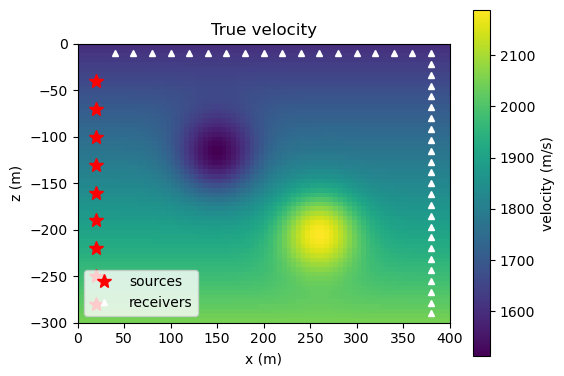

In [3]:
x, z = core.cell_centers.T
v_true = 1600.0 + 1.5 * (-z)
v_true *= 1 - 0.15 * np.exp(-((x - 150) ** 2 + (z + 120) ** 2) / (2 * 30**2))
v_true *= 1 + 0.15 * np.exp(-((x - 260) ** 2 + (z + 200) ** 2) / (2 * 30**2))
m_true = np.log(v_true)

sources = np.c_[np.full(9, 20.0), np.linspace(-280, -40, 9)]
receivers = np.vstack(
    [
        np.c_[np.full(25, 380.0), np.linspace(-290, -10, 25)],
        np.c_[np.linspace(40, 360, 17), np.full(17, -10.0)],
    ]
)
clim = (v_true.min(), v_true.max())


def plot_velocity(ax, v, title):
    out = core.plot_image(v, ax=ax, clim=clim, pcolor_opts={"cmap": "viridis"})
    ax.set_aspect("equal")
    ax.set_xlabel("x (m)")
    ax.set_ylabel("z (m)")
    ax.set_title(title)
    return out


fig, ax = plt.subplots(figsize=(6, 4.5))
out = plot_velocity(ax, v_true, "True velocity")
ax.plot(*sources.T, "r*", ms=10, label="sources")
ax.plot(*receivers.T, "w^", ms=5, label="receivers")
ax.legend(loc="lower left")
plt.colorbar(out[0], ax=ax, label="velocity (m/s)");

## Step 1: traveltime tomography

First-arrival traveltimes from the eikonal simulation, with 0.2 ms of noise,
inverted for a smooth log-velocity model starting from a homogeneous one.

In [4]:
tt_survey = traveltime.Survey(
    [
        traveltime.sources.PointSource(
            [traveltime.receivers.Traveltime(receivers)], location=s
        )
        for s in sources
    ]
)
tt_sim = traveltime.SimulationEikonal(
    core, survey=tt_survey, slownessMap=maps.ReciprocalMap(core) * maps.ExpMap(core)
)
tt_data = tt_sim.make_synthetic_data(
    m_true, relative_error=0.0, noise_floor=2e-4, add_noise=True, random_seed=1
)

m_homogeneous = np.full(core.n_cells, np.log(np.median(v_true)))
inv = inversion.BaseInversion(
    inverse_problem.BaseInvProblem(
        data_misfit.L2DataMisfit(data=tt_data, simulation=tt_sim),
        regularization.WeightedLeastSquares(
            core, reference_model=m_homogeneous, alpha_s=1e-3
        ),
        optimization.InexactGaussNewton(maxIter=15, cg_maxiter=30),
    ),
    directiveList=[
        directives.BetaEstimate_ByEig(beta0_ratio=10, random_seed=0),
        directives.BetaSchedule(coolingFactor=2, coolingRate=1),
        directives.TargetMisfit(),
    ],
)
m_traveltime = inv.run(m_homogeneous)

INFO: 
simpeg.InvProblem is setting bfgsH0 to the inverse of the reg.deriv2.
using the default solver Mumps with the 'is_symmetric=True` option set.



INFO: Directive TargetMisfit: Target data misfit is 378.0



Running inversion with SimPEG v0.25.2
============================ Inexact Gauss Newton ============================
  #     beta     phi_d     phi_m       f      |proj(x-g)-x|  LS    Comment   
-----------------------------------------------------------------------------
   0  6.42e+03  1.14e+06  1.47e-26  1.14e+06                                 


   1  6.42e+03  4.01e+04  2.74e+00  5.77e+04    5.28e+05      0              
   2  3.21e+03  2.44e+03  3.44e+00  1.35e+04    7.72e+04      0              


   3  1.61e+03  9.39e+02  3.76e+00  6.98e+03    1.33e+04      0   Skip BFGS  


   4  8.03e+02  6.58e+02  4.00e+00  3.86e+03    6.26e+03      0   Skip BFGS  


   5  4.01e+02  5.21e+02  4.23e+00  2.22e+03    5.95e+03      0   Skip BFGS  


   6  2.01e+02  4.36e+02  4.53e+00  1.34e+03    5.62e+03      0   Skip BFGS  


   7  1.00e+02  3.67e+02  5.00e+00  8.68e+02    5.01e+03      0   Skip BFGS  
------------------------- STOP! -------------------------
1 : |fc-fOld| = 2.1654e+01 <= tolF*(1+|f0|) = 1.1445e+05
1 : |xc-x_last| = 2.3215e-01 <= tolX*(1+|x0|) = 5.2098e+01
0 : |proj(x-g)-x|    = 5.0148e+03 <= tolG          = 1.0000e-01
0 : |proj(x-g)-x|    = 5.0148e+03 <= 1e3*eps       = 1.0000e-02
0 : maxIter   =      15    <= iter          =      7
------------------------- DONE! -------------------------


RMS velocity error: homogeneous 154 m/s, traveltime tomography 45 m/s


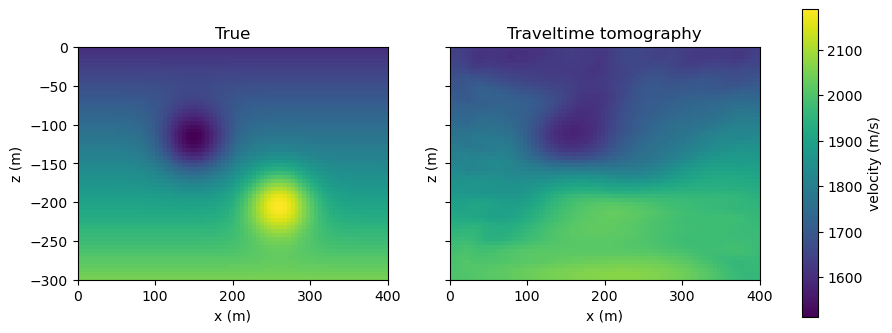

In [5]:
def rms_error(m):
    return np.sqrt(np.mean((np.exp(m) - v_true) ** 2))


fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
plot_velocity(axes[0], v_true, "True")
out = plot_velocity(axes[1], np.exp(m_traveltime), "Traveltime tomography")
plt.colorbar(out[0], ax=axes, label="velocity (m/s)")
print(
    f"RMS velocity error: homogeneous {rms_error(m_homogeneous):.0f} m/s, "
    f"traveltime tomography {rms_error(m_traveltime):.0f} m/s"
)

The traveltime model gets the background and the slow anomaly roughly
right, but it is smooth: first arrivals bend around the slow anomaly and
are only weakly sensitive to the fast one.

## Step 2: the frequency-domain simulation

Each source is a point source with a 10 Hz Ricker waveform: at each
frequency its amplitude is the waveform's spectrum. Receivers record the real and imaginary
parts of the pressure. Here is the wavefield of one source at 7 Hz in the true
model, including the PML padding, where it decays.

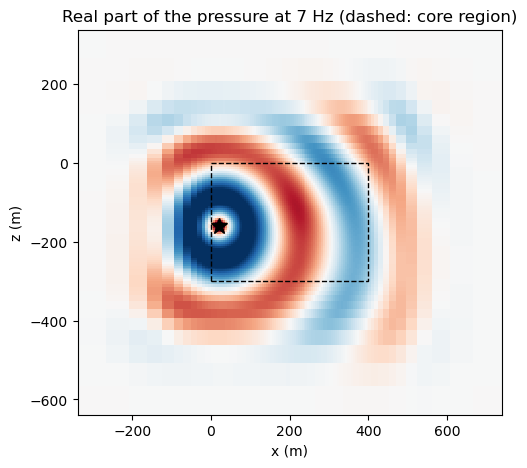

In [6]:
waveform = wavelets.RickerWaveform(peak_frequency=10.0)


def fwi_survey(frequencies):
    rx = [
        frequency_domain.receivers.Pressure(receivers, component="real"),
        frequency_domain.receivers.Pressure(receivers, component="imag"),
    ]
    return frequency_domain.Survey(
        [
            frequency_domain.sources.PointSource(
                rx,
                location=s,
                frequency=f,
                waveform=waveform,
            )
            for f in frequencies
            for s in sources
        ]
    )


def fwi_simulation(frequencies):
    return frequency_domain.SimulationAcoustic(
        mesh,
        survey=fwi_survey(frequencies),
        slownessMap=maps.ReciprocalMap(mesh) * maps.ExpMap(mesh) * extend,
        pml_velocity=2200.0,
        pml_cells=n_pad,
        solver=get_default_solver(),
    )


sim = fwi_simulation([7.0])
p = sim.fields(m_true)[sim.survey.source_list[4], "p"][:, 0]
fig, ax = plt.subplots(figsize=(7, 5))
out = mesh.plot_image(
    p.real, v_type="N", ax=ax, pcolor_opts={"cmap": "RdBu_r"},
    clim=np.r_[-1, 1] * np.abs(p.real).max() / 4,
)
ax.add_patch(plt.Rectangle((0, -300), 400, 300, fill=False, ls="--", color="k"))
ax.plot(*sources[4], "k*", ms=12)
ax.set_aspect("equal")
ax.set_xlabel("x (m)")
ax.set_ylabel("z (m)")
ax.set_title("Real part of the pressure at 7 Hz (dashed: core region)");

## Step 3: multi-frequency FWI

Four bands, from 4-5 Hz up to 12-14 Hz. Each band is a separate inversion
that starts from the result of the previous one. The data have 1% noise.
The regularization keeps the model smooth and close to the traveltime
model; the data have to justify any detail.

In [7]:
bands = [(4.0, 5.0), (6.0, 7.0), (8.0, 10.0), (12.0, 14.0)]
m = m_traveltime.copy()
models = {"traveltime": m_traveltime}

for i, frequencies in enumerate(bands):
    sim = fwi_simulation(frequencies)
    noise_floor = 0.01 * np.sqrt(np.mean(sim.dpred(m_true) ** 2))
    data = sim.make_synthetic_data(
        m_true, relative_error=0.01, noise_floor=noise_floor, add_noise=True,
        random_seed=i,
    )
    inv = inversion.BaseInversion(
        inverse_problem.BaseInvProblem(
            data_misfit.L2DataMisfit(data=data, simulation=sim),
            regularization.WeightedLeastSquares(
                core, reference_model=m_traveltime, alpha_s=1e-4
            ),
            optimization.InexactGaussNewton(maxIter=8, cg_maxiter=15),
        ),
        directiveList=[
            directives.BetaEstimate_ByEig(beta0_ratio=1, random_seed=0),
            directives.BetaSchedule(coolingFactor=2, coolingRate=1),
            directives.TargetMisfit(),
        ],
    )
    m = inv.run(m)
    models[f"{frequencies[0]:g}-{frequencies[1]:g} Hz"] = m
    print(f"after {frequencies} Hz: RMS velocity error {rms_error(m):.0f} m/s\n")

INFO: 
simpeg.InvProblem is setting bfgsH0 to the inverse of the reg.deriv2
using the same solver as the SimulationAcoustic simulation with the 'is_symmetric=True` option set.




Running inversion with SimPEG v0.25.2


INFO: Directive TargetMisfit: Target data misfit is 1512.0


============================ Inexact Gauss Newton ============================
  #     beta     phi_d     phi_m       f      |proj(x-g)-x|  LS    Comment   
-----------------------------------------------------------------------------
   0  2.18e+03  9.43e+03  4.22e+00  1.86e+04                                 


   1  2.18e+03  2.05e+03  2.70e+00  7.95e+03    6.59e+04      0              


...

   1  4.53e+03  2.69e+03  3.83e+00  2.00e+04    3.73e+04      0              


   2  2.27e+03  1.92e+03  4.04e+00  1.11e+04    9.97e+03      0              


   3  1.13e+03  1.68e+03  4.18e+00  6.42e+03    4.67e+03      0   Skip BFGS  


   4  5.66e+02  1.57e+03  4.30e+00  4.01e+03    3.83e+03      0   Skip BFGS  


   5  2.83e+02  1.50e+03  4.47e+00  2.76e+03    3.35e+03      0   Skip BFGS  
------------------------- STOP! -------------------------
1 : |fc-fOld| = 3.2453e+01 <= tolF*(1+|f0|) = 2.3901e+03
1 : |xc-x_last| = 9.4276e-02 <= tolX*(1+|x0|) = 5.2104e+01
0 : |proj(x-g)-x|    = 3.3497e+03 <= tolG          = 1.0000e-01
0 : |proj(x-g)-x|    = 3.3497e+03 <= 1e3*eps       = 1.0000e-02
0 : maxIter   =       8    <= iter          =      5
------------------------- DONE! -------------------------
after (12.0, 14.0) Hz: RMS velocity error 25 m/s



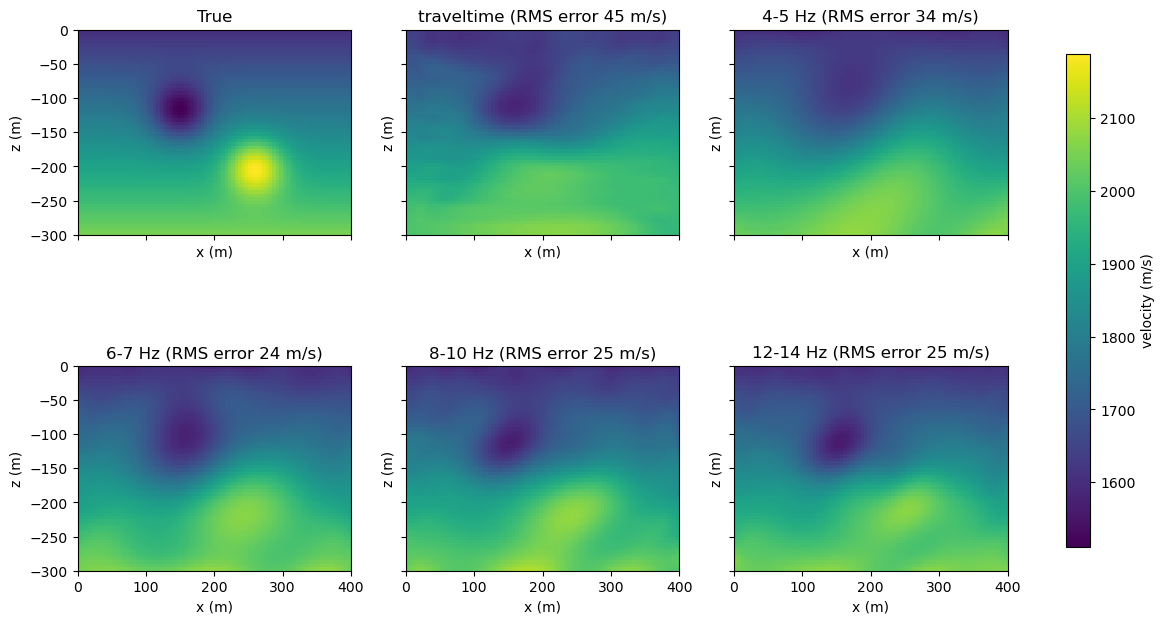

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)
plot_velocity(axes[0, 0], v_true, "True")
for ax, (name, model) in zip(axes.flat[1:], models.items()):
    out = plot_velocity(ax, np.exp(model), f"{name} (RMS error {rms_error(model):.0f} m/s)")
plt.colorbar(out[0], ax=axes, label="velocity (m/s)", shrink=0.8);

The first band (4-5 Hz) has wavelengths of 350-450 m, so it only updates
the long-wavelength structure and its model is smoother than the traveltime
one. Each higher band adds detail: by 12-14 Hz the slow anomaly is sharp and
much of the fast anomaly, which traveltime tomography could barely see, is
recovered. A vertical profile through both anomalies shows the improvement.

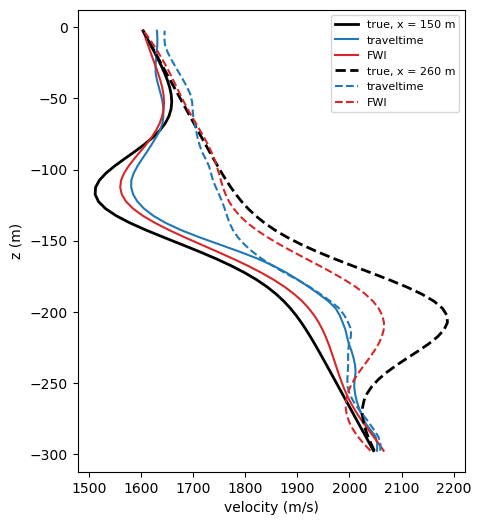

In [9]:
fig, ax = plt.subplots(figsize=(5, 6))
for x0, style in ((150.0, "-"), (260.0, "--")):
    column = np.isclose(x, x0 + h / 2)
    depth = z[column]
    ax.plot(v_true[column], depth, "k" + style, lw=2, label=f"true, x = {x0:g} m")
    ax.plot(np.exp(m_traveltime[column]), depth, "C0" + style, label="traveltime")
    ax.plot(np.exp(m[column]), depth, "C3" + style, label="FWI")
ax.set_xlabel("velocity (m/s)")
ax.set_ylabel("z (m)")
ax.legend(fontsize=8);

## Cycle skipping

The same FWI, but starting from the homogeneous model and using only the
highest band (12-14 Hz). The predicted waves are many periods out of phase
with the observed ones, so the inversion converges to a wrong model and
cannot fit the data.

INFO: 
simpeg.InvProblem is setting bfgsH0 to the inverse of the reg.deriv2
using the same solver as the SimulationAcoustic simulation with the 'is_symmetric=True` option set.




Running inversion with SimPEG v0.25.2


INFO: Directive TargetMisfit: Target data misfit is 1512.0


============================ Inexact Gauss Newton ============================
  #     beta     phi_d     phi_m       f      |proj(x-g)-x|  LS    Comment   
-----------------------------------------------------------------------------
   0  3.46e+03  5.98e+06  1.47e-26  5.98e+06                                 


   1  3.46e+03  1.02e+06  1.87e+01  1.09e+06    2.65e+06      0              


...

   4  4.32e+02  4.43e+04  1.18e+01  4.94e+04    2.07e+05      0              


   5  2.16e+02  3.87e+04  1.52e+01  4.20e+04    1.73e+05      0              


   6  1.08e+02  3.42e+04  2.19e+01  3.65e+04    1.52e+05      0              


   7  5.40e+01  2.90e+04  2.99e+01  3.06e+04    1.36e+05      0              


   8  2.70e+01  2.45e+04  4.36e+01  2.57e+04    1.18e+05      0              
------------------------- STOP! -------------------------
1 : |fc-fOld| = 4.1181e+03 <= tolF*(1+|f0|) = 5.9794e+05
1 : |xc-x_last| = 1.0490e+00 <= tolX*(1+|x0|) = 5.2098e+01
0 : |proj(x-g)-x|    = 8.6855e+04 <= tolG          = 1.0000e-01
0 : |proj(x-g)-x|    = 8.6855e+04 <= 1e3*eps       = 1.0000e-02
1 : maxIter   =       8    <= iter          =      8
------------------------- DONE! -------------------------

phi_d = 24527 for 1512 data (target 1512)
RMS velocity error 132 m/s


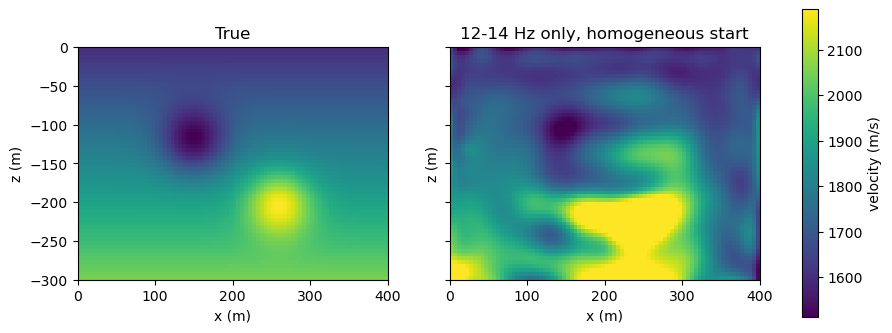

In [10]:
sim = fwi_simulation(bands[-1])
noise_floor = 0.01 * np.sqrt(np.mean(sim.dpred(m_true) ** 2))
data = sim.make_synthetic_data(
    m_true, relative_error=0.01, noise_floor=noise_floor, add_noise=True,
    random_seed=9,
)
misfit = data_misfit.L2DataMisfit(data=data, simulation=sim)
inv = inversion.BaseInversion(
    inverse_problem.BaseInvProblem(
        misfit,
        regularization.WeightedLeastSquares(
            core, reference_model=m_homogeneous, alpha_s=1e-4
        ),
        optimization.InexactGaussNewton(maxIter=8, cg_maxiter=15),
    ),
    directiveList=[
        directives.BetaEstimate_ByEig(beta0_ratio=1, random_seed=0),
        directives.BetaSchedule(coolingFactor=2, coolingRate=1),
        directives.TargetMisfit(),
    ],
)
m_skipped = inv.run(m_homogeneous)
print(f"\nphi_d = {misfit(m_skipped):.0f} for {data.nD} data (target {data.nD})")

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
plot_velocity(axes[0], v_true, "True")
out = plot_velocity(axes[1], np.exp(m_skipped), "12-14 Hz only, homogeneous start")
print(f"RMS velocity error {rms_error(m_skipped):.0f} m/s")
plt.colorbar(out[0], ax=axes, label="velocity (m/s)");